<a href="https://colab.research.google.com/github/sileysa/Semester_5/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Instalasi dan import library

In [1]:
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 2. Memuat dataset Iris

In [2]:
# Memuat dataset Iris
iris = load_iris()

# Fitur yang digunakan untuk clustering
X = iris.data

# Label spesies asli, hanya untuk analisis
y_true = iris.target

# Nama fitur
feature_names = iris.feature_names

# Nama spesies
target_names = iris.target_names

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", feature_names)
print("Label asli:", target_names)

print("\nJumlah setiap spesies:")
print(pd.Series(y_true).map(dict(enumerate(target_names))).value_counts())

Jumlah data: 150
Jumlah fitur: 4
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: ['setosa' 'versicolor' 'virginica']

Jumlah setiap spesies:
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# 3. Normalisasi data

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Normalisasi berhasil!")
print("Ukuran data:", X_scaled.shape)

Normalisasi berhasil!
Ukuran data: (150, 4)


# 4. Membuat model HDBSCAN

In [4]:
# Membuat model HDBSCAN
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

# Melakukan clustering
labels = hdb.fit_predict(X_scaled)

print("Clustering selesai!")

Clustering selesai!


# 5. Menghitung jumlah cluster dan noise

In [5]:
# Mengambil label cluster selain -1
cluster_labels = set(labels)
cluster_labels.discard(-1)

# Menghitung jumlah cluster dan noise
n_clusters = len(cluster_labels)
n_noise = np.sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)
print("Jumlah data:", len(labels))

print("\nJumlah data pada setiap cluster:")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster: 2
Jumlah noise: 2
Jumlah data: 150

Jumlah data pada setiap cluster:
-1     2
 0    99
 1    49
Name: count, dtype: int64


# 6. Visualisasi menggunakan PCA

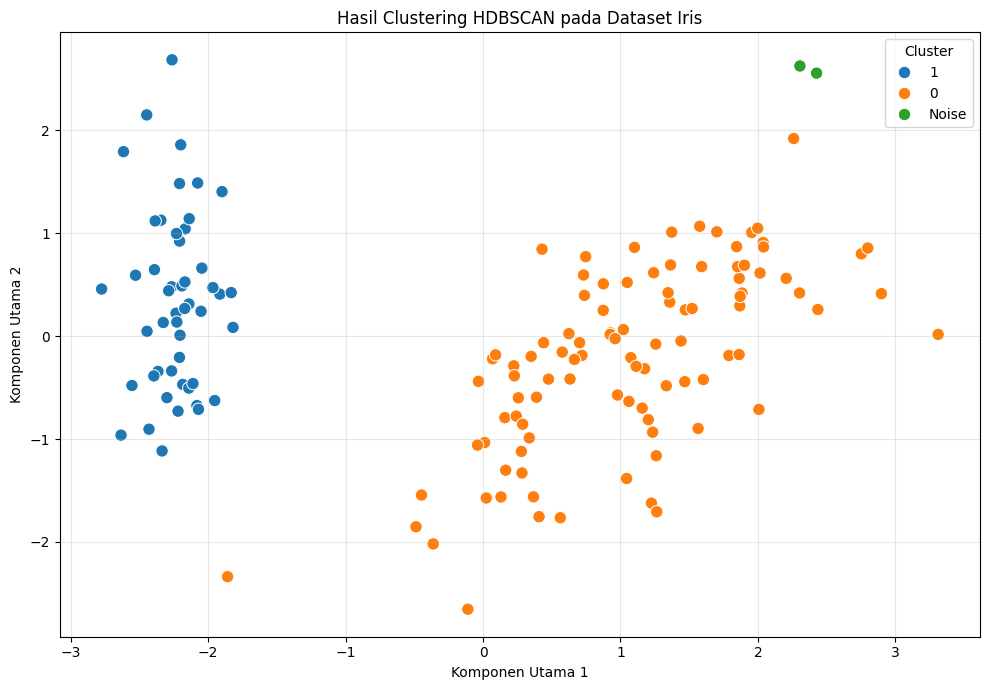

Variansi yang dijelaskan PCA:
[0.72962445 0.22850762]
Total variansi yang dijelaskan: 0.9581


In [6]:
# Reduksi dimensi menjadi 2 komponen
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Membuat DataFrame untuk visualisasi
df_plot = pd.DataFrame({
    "PCA 1": X_pca[:, 0],
    "PCA 2": X_pca[:, 1],
    "Cluster": labels.astype(str)
})

# Mengubah label noise agar mudah dibaca
df_plot.loc[labels == -1, "Cluster"] = "Noise"

# Membuat scatterplot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_plot,
    x="PCA 1",
    y="PCA 2",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("Hasil Clustering HDBSCAN pada Dataset Iris")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Informasi kontribusi PCA
print("Variansi yang dijelaskan PCA:")
print(pca.explained_variance_ratio_)

print(
    "Total variansi yang dijelaskan:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# 7. Membandingkan hasil cluster dengan label asli

In [7]:
df_comparison = pd.DataFrame({
    "Spesies Asli": [target_names[i] for i in y_true],
    "Cluster HDBSCAN": labels
})

print("Perbandingan spesies asli dan cluster HDBSCAN:")

display(
    pd.crosstab(
        df_comparison["Spesies Asli"],
        df_comparison["Cluster HDBSCAN"],
        margins=True
    )
)

Perbandingan spesies asli dan cluster HDBSCAN:


Cluster HDBSCAN,-1,0,1,All
Spesies Asli,,,,
setosa,0,1,49,50
versicolor,0,50,0,50
virginica,2,48,0,50
All,2,99,49,150


In [8]:
ari = adjusted_rand_score(y_true, labels)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")

Adjusted Rand Index (ARI): 0.5394


### Analisis Hasil

Berdasarkan proses clustering menggunakan algoritma HDBSCAN pada dataset Iris yang terdiri dari 150 data dan empat fitur, diperoleh dua cluster utama dan dua data noise. Cluster 0 terdiri dari 99 data, sedangkan cluster 1 terdiri dari 49 data. Dua data lainnya dikategorikan sebagai noise karena tidak memenuhi kriteria kepadatan untuk dimasukkan ke dalam cluster.

Visualisasi menggunakan Principal Component Analysis (PCA) menunjukkan bahwa kedua cluster memiliki pemisahan yang cukup jelas. Berdasarkan perbandingan dengan label spesies asli, sebanyak 49 dari 50 data setosa berhasil dikelompokkan ke dalam cluster 1. Sementara itu, seluruh data versicolor dan sebagian besar data virginica masuk ke cluster 0. Dua data virginica lainnya dikategorikan sebagai noise.

Nilai Adjusted Rand Index (ARI) yang diperoleh sebesar 0,5394. Nilai tersebut menunjukkan bahwa hasil clustering memiliki tingkat kesesuaian sedang terhadap label spesies asli. HDBSCAN mampu memisahkan sebagian besar data setosa dengan baik, tetapi belum berhasil membedakan spesies versicolor dan virginica secara optimal. Hal ini dapat terjadi karena kedua spesies tersebut memiliki karakteristik fitur yang saling berdekatan.

### Kesimpulan

Berdasarkan percobaan yang telah dilakukan, algoritma HDBSCAN berhasil membentuk dua cluster dari dataset Iris dengan dua data noise. Hasil clustering menunjukkan kesesuaian sedang dengan label spesies asli berdasarkan nilai ARI sebesar 0,5394. Algoritma ini mampu mengelompokkan sebagian besar data setosa secara terpisah, tetapi masih menggabungkan data versicolor dan virginica ke dalam satu cluster. Dengan demikian, hasil clustering HDBSCAN belum sepenuhnya sesuai dengan pengelompokan spesies asli pada dataset Iris.